# MotionProof AI
## Deliverable 3: Refinement and Extended Evaluation

This notebook documents what changed between Deliverable 2 (D2) and Deliverable 3 (D3) and produces the D3 results that are compared with D2.

**Pipeline:** PPG → CNN heart-rate estimate → 14 reliability features → gradient-boosted reliability classifier → fitted Q-learning investigation agent → `ACCEPT` or `FLAG_UNRELIABLE`.

**Rules followed in this notebook**

| Rule | How it is enforced |
|---|---|
| The D2 checkpoints and D2 test results stay frozen | SHA-256 check in Section 2; nothing is written to `checkpoints/` or `results/` |
| Every D3 choice is made on validation participants S11–S12 only | assertions on subject IDs before any fitting or selection |
| Test participants S13–S15 are used once, for reporting | Section 9 |
| The chest-ECG reference heart rate never enters the model, the classifier or the agent | it is used only to compute labels and metrics |

**What is recomputed here and what is loaded**

- *Recomputed:* the full inference pipeline on all 13,007 test windows, the calibration study (leave-one-participant-out selection, refit, test scoring), every false-positive reduction candidate, replays of all 18 retrained policies on validation and of the selected ones on test, the D2-vs-D3 comparison, motion-quartile analysis and the qualitative examples.
- *Loaded from saved outputs:* the training of the 18 reward-variant policies (about 5 minutes each; their checkpoints and training histories are in `checkpoints/experimental/policies/`) and the 18-condition synthetic robustness study (`src/experiments/run_robustness.py`).

Every recomputed number is checked against the saved D3 result files with `assert`, so a successful run is also a reproducibility check.

Sections 4, 5, 8 and 10 need the processed recordings in `data/processed/val/` and `data/processed/test/` (not redistributed in this repository; see the README). Without them the notebook still runs and falls back to the saved outputs, and says so.

## 1. Environment

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run from the project root or the notebooks directory."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.agents.fitted_q_inference import load_fitted_q_policy
from src.agents.investigation_environment import InvestigationEnvironment
from src.evaluation.generate_validation_predictions import load_cnn, predict_cnn
from src.evaluation.reliability_baseline import FEATURE_COLUMNS
from src.evaluation.reliability_features import extract_reliability_features
from src.experiments import verify_frozen
from src.experiments.calibration import (calibration_metrics, leave_one_subject_out,
                                         make_calibrator, reliability_table)
from src.experiments.common import (TEST_INPUTS, TEST_SUBJECTS, VALIDATION_INPUTS,
                                    VALIDATION_SUBJECTS, assert_no_test_subjects,
                                    classification_metrics, load_config, set_seed)
from src.experiments.policy_evaluation import load_split, replay_policy
from src.experiments.robustness import apply as perturb, motion_intensity
from src.experiments.run_fp_reduction import (TEST_DECISIONS, VAL_DECISIONS, candidate_rows,
                                              frozen_learned, seed_means, select)
from src.experiments.train_reward_variants import variant_path

%matplotlib inline
# (re-enable inline plots: the imported experiment scripts select a file-only backend)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

EXP = ROOT / "results" / "experiments"
FINAL = ROOT / "results" / "metrics" / "final_test"
KEYS = ["subject", "window_index"]
set_seed(42)

pins = dict(line.split("==") for line in (ROOT / "requirements.txt").read_text().splitlines()
            if "==" in line and not line.startswith("#"))
installed = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
             "torch": torch.__version__.split("+")[0], "joblib": joblib.__version__}
env = pd.DataFrame([{"package": k, "required": pins.get(k), "installed": v,
                     "match": pins.get(k) == v} for k, v in installed.items()])
print("Project folder:", ROOT.name)
print("Python:", sys.version.split()[0])
display(env)

Project folder: nb_work
Python: 3.12.3


,package,required,installed,match
0,numpy,1.26.4,1.26.4,True
1,pandas,2.3.3,2.3.3,True
2,scikit-learn,1.4.0,1.4.0,True
3,torch,2.15.0,2.15.0,True
4,joblib,1.3.2,1.3.2,True


## 2. Frozen D2 artifacts are unchanged

`configs/frozen_artifacts.json` records the SHA-256 of the D2 checkpoints and D2 evaluation files. Any change to them would invalidate the D2-vs-D3 comparison, so the notebook stops if one has changed.

In [2]:
count, problems = verify_frozen.check()
assert not problems, problems
registry = json.loads((ROOT / "configs/frozen_artifacts.json").read_text())["files"]
print(f"All {count} frozen artifacts match their recorded SHA-256.")
display(pd.DataFrame({"file": list(registry), "sha256 (first 12)": [h[:12] for h in registry.values()]}))

All 15 frozen artifacts match their recorded SHA-256.


,file,sha256 (first 12)
0,checkpoints/learned_policy_fitted_q_full.pt,7058bb0d94f7
1,checkpoints/ppg_cnn_best.pt,af193b6d5fe3
2,checkpoints/reliability_classifier_nonlinear_f...,82f98d732a09
3,results/metrics/final_test/investigation_actio...,ef04ca77ab50
4,results/metrics/final_test/investigation_actio...,41c9f5509860
5,results/metrics/final_test/investigation_budge...,d2bf1edb5c35
6,results/metrics/final_test/investigation_budge...,6dc454f04dd5
7,results/metrics/final_test/ppg_noise_robustnes...,439de79d14e0
8,results/metrics/final_test/ppg_noise_robustnes...,afdbe9489612
9,results/metrics/final_test/reproducibility_man...,80df2b88fea1


## 3. Data splits

Participants are split, not windows, so no person appears in two splits. A window is labelled *unreliable* when the CNN's absolute error against the chest-ECG reference exceeds 10 BPM.

In [3]:
val_inputs = pd.read_csv(VALIDATION_INPUTS)
test_inputs = pd.read_csv(TEST_INPUTS)
assert_no_test_subjects(val_inputs)
assert set(val_inputs.subject) == set(VALIDATION_SUBJECTS)
assert set(test_inputs.subject) == set(TEST_SUBJECTS)
assert ((test_inputs.absolute_error > 10).astype(int) == test_inputs.unreliable_target).all()

splits = pd.DataFrame([
    {"split": "train", "participants": "S1–S10", "used for": "CNN, classifier and policy training (D2); reward-variant retraining (D3)",
     "windows": "—", "unreliable rate": "—"},
    {"split": "validation", "participants": "S11–S12", "used for": "calibration fitting, all D3 selection",
     "windows": len(val_inputs), "unreliable rate": f"{val_inputs.unreliable_target.mean():.1%}"},
    {"split": "test", "participants": "S13–S15", "used for": "one final report only",
     "windows": len(test_inputs), "unreliable rate": f"{test_inputs.unreliable_target.mean():.1%}"},
])
display(splits)

DATA_AVAILABLE = all((ROOT / f"data/processed/{folder}/S{s}.npz").is_file()
                     for folder, subs in (("val", VALIDATION_SUBJECTS), ("test", TEST_SUBJECTS)) for s in subs)
print("Processed recordings available:", DATA_AVAILABLE)

,split,participants,used for,windows,unreliable rate
0,train,S1–S10,"CNN, classifier and policy training (D2); rewa...",—,—
1,validation,S11–S12,"calibration fitting, all D3 selection",8475,33.7%
2,test,S13–S15,one final report only,13007,13.9%


Processed recordings available: True


## 4. End-to-end pipeline on all held-out test windows

This runs the complete chain on the raw processed windows: CNN → features → classifier → frozen agent. It shows that the pipeline still runs end to end and reproduces the frozen D2 inputs and decisions.

In [4]:
if DATA_AVAILABLE:
    test_signals = load_split("test")[1]
    for s_ in TEST_SUBJECTS:  # reference HR: used below only to score the pipeline, never as an input
        with np.load(ROOT / f"data/processed/test/S{s_}.npz") as data:
            test_signals[s_]["hr"] = data["hr"].copy()
    cnn, mean, std = load_cnn("cpu")
    classifier = joblib.load(ROOT / "checkpoints/reliability_classifier_nonlinear_full.joblib")
    agent = load_fitted_q_policy(ROOT / "checkpoints/learned_policy_fitted_q_full.pt", device="cpu")

    start = time.perf_counter()
    live = []
    for subject, sig in test_signals.items():
        with torch.no_grad():
            hr = np.asarray(predict_cnn(model=cnn, ppg=sig["ppg"], mean=mean, std=std, device="cpu"),
                            dtype=np.float64).reshape(-1)
        feats = extract_reliability_features(sig["ppg"], sig["acc"])
        prob = classifier.predict_proba(pd.DataFrame(np.column_stack([feats, hr]), columns=FEATURE_COLUMNS))[:, 1]
        live.append(pd.DataFrame({"subject": subject, "window_index": np.arange(len(hr)),
                                  "live_hr": hr, "live_probability": prob, "reference_hr": sig["hr"]}))
    live = pd.concat(live, ignore_index=True)
    batch_seconds = time.perf_counter() - start

    check = live.merge(test_inputs, on=KEYS, suffixes=("", "_frozen"))
    live_target = (np.abs(check.live_hr - check.reference_hr) > 10).astype(int)
    dp = np.abs(check.live_probability - check.unreliable_probability)
    summary = pd.Series({
        "windows": len(check),
        "CNN MAE (BPM)": np.abs(check.live_hr - check.reference_hr).mean(),
        "max |HR live - frozen| (BPM)": np.abs(check.live_hr - check.cnn_predicted_hr).max(),
        "max |p live - frozen|": dp.max(),
        "windows with |Δp| > 0.01": int((dp > 0.01).sum()),
        "unreliable labels changed": int((live_target != check.unreliable_target).sum()),
        "No-Investigation decisions changed": int(((check.live_probability >= .5) != (check.unreliable_probability >= .5)).sum()),
        "CNN + features + classifier, all windows (s)": batch_seconds,
    })
    display(summary.to_frame("value"))
    assert summary["unreliable labels changed"] == 0
    assert abs(summary["CNN MAE (BPM)"] - 5.40) < 0.005

    start = time.perf_counter()
    replay = replay_policy(agent, test_inputs, test_signals)
    replay_seconds = time.perf_counter() - start
    frozen_agent = frozen_learned(TEST_DECISIONS)
    agree = replay.merge(frozen_agent, on=KEYS, suffixes=("", "_frozen"))
    agreement = (agree.predicted_unreliable == agree.predicted_unreliable_frozen).mean()
    print(f"Frozen agent replayed on {len(agree):,} windows in {replay_seconds:.1f} s; "
          f"decision agreement with frozen D2 decisions: {agreement:.2%}")
    assert agreement == 1.0
else:
    print("Processed recordings not found: end-to-end run skipped. "
          "The saved clean re-run in results/experiments/phase3_robustness reproduced 100% of frozen agent decisions.")

,value
windows,13007.000000
CNN MAE (BPM),5.400707
max |HR live - frozen| (BPM),0.011185
max |p live - frozen|,0.045047
windows with |Δp| > 0.01,8.000000
unreliable labels changed,0.000000
No-Investigation decisions changed,0.000000
"CNN + features + classifier, all windows (s)",3.659491


Frozen agent replayed on 13,007 windows in 6.8 s; decision agreement with frozen D2 decisions: 100.00%


A few classifier probabilities differ in the third decimal from the frozen D2 file because of floating-point differences between batched and per-window CNN inference. None of these differences changes a label or a decision.

**Single-window latency.** The interface analyses one window at a time, so the time a user waits is measured the same way.

In [5]:
if DATA_AVAILABLE:
    sig = test_signals[13]
    hist_hr = test_inputs[test_inputs.subject == 13].sort_values("window_index").cnn_predicted_hr.to_numpy()
    timings = []
    for w in range(200, 400):
        t0 = time.perf_counter()
        with torch.no_grad():
            hr_w = float(np.asarray(predict_cnn(model=cnn, ppg=sig["ppg"][w].reshape(1, -1), mean=mean,
                                                std=std, device="cpu")).reshape(-1)[0])
        f = extract_reliability_features(sig["ppg"][w].reshape(1, -1), sig["acc"][w].reshape(1, 256, 3))
        p_w = float(classifier.predict_proba(pd.DataFrame(np.column_stack([f, [hr_w]]), columns=FEATURE_COLUMNS))[0, 1])
        agent.run(InvestigationEnvironment(ppg_window=sig["ppg"][w], acc_window=sig["acc"][w], cnn_predicted_hr=hr_w,
                                           unreliable_probability=p_w, previous_hr_predictions=hist_hr[w - 5:w], budget=2))
        timings.append((time.perf_counter() - t0) * 1000)
    print(f"Single-window pipeline on CPU over 200 windows: median {np.median(timings):.1f} ms, "
          f"95th percentile {np.percentile(timings, 95):.1f} ms")

Single-window pipeline on CPU over 200 windows: median 3.6 ms, 95th percentile 5.3 ms


## 5. Refined preprocessing and feature engineering

D3 adds two inputs to the decision layer and the evaluation, without changing the frozen D2 inference path:

1. **Calibrated failure probability** $p_{cal}$: a Platt map fitted on validation (Section 6). It feeds the D3 threshold baselines and the optional calibrated veto. The frozen agent still sees the original probability.
2. **Motion intensity**: the standard deviation of the accelerometer magnitude in each 8-s window, in g. It is used to stratify results by how much the wearer was moving, because activity labels are not part of the processed windows.

D3 also adds a **perturbation stage** that corrupts copies of the held-out recordings in controlled ways (noise, motion artifacts, wander, attenuation, dropout, clipping) for the robustness study in Section 10.

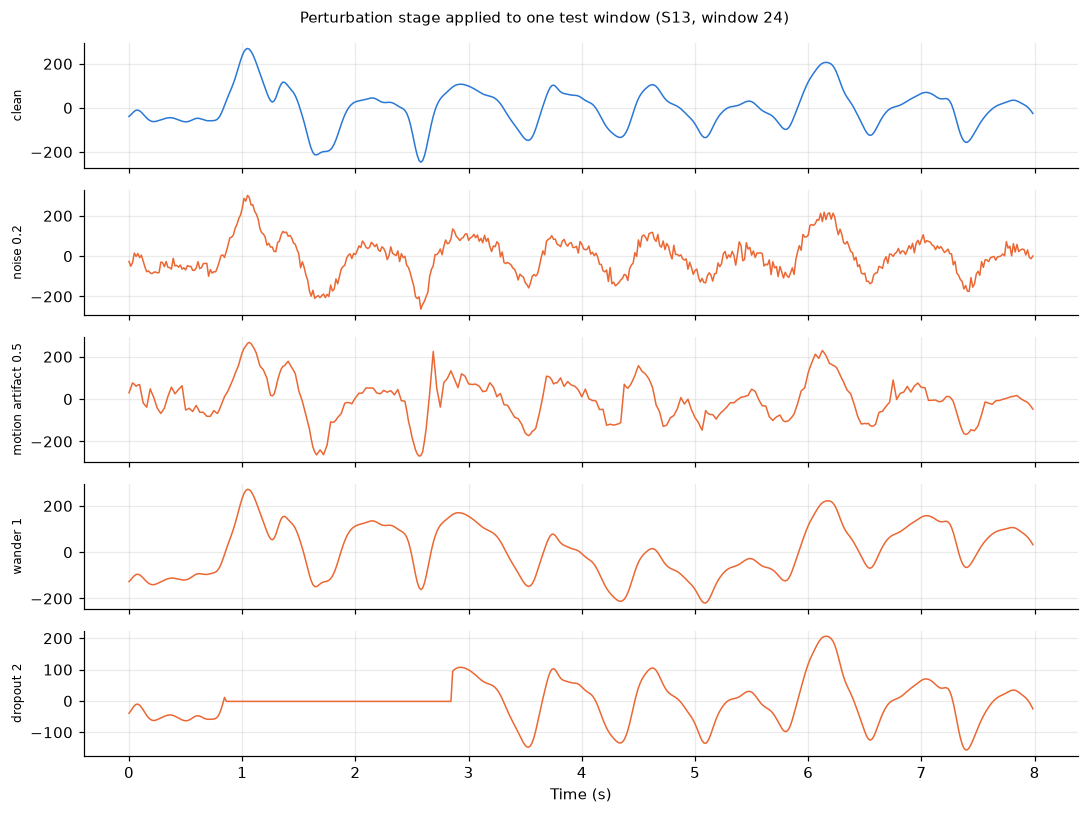

          count   mean    std  min    25%    50%    75%    max
subject                                                       
13       4565.0  0.135  0.118  0.0  0.023  0.100  0.236  0.565
14       4476.0  0.123  0.111  0.0  0.025  0.084  0.209  0.536
15       3966.0  0.148  0.146  0.0  0.014  0.085  0.285  0.581


In [6]:
if DATA_AVAILABLE:
    s, w = 13, 24
    ppg0, acc0 = test_signals[s]["ppg"][w:w + 1], test_signals[s]["acc"][w:w + 1]
    examples = [("clean", 0.0), ("gaussian_noise", 0.2), ("accelerometer_coupled_artifact", 0.5),
                ("baseline_wander", 1.0), ("signal_dropout", 2.0)]
    t = np.arange(ppg0.shape[1]) / 64
    fig, axes = plt.subplots(len(examples), 1, figsize=(10, 7.5), sharex=True)
    for ax, (name, level) in zip(axes, examples):
        p_, a_ = (ppg0, acc0) if name == "clean" else perturb(name, ppg0, acc0, level, seed=1000 + s)
        ax.plot(t, p_[0], color=BLUE if name == "clean" else ORANGE, lw=1)
        short = {"clean": "clean", "gaussian_noise": "noise", "accelerometer_coupled_artifact": "motion artifact",
                 "baseline_wander": "wander", "signal_dropout": "dropout"}[name]
        ax.set_ylabel(short + ("" if name == "clean" else f" {level:g}"), fontsize=8)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(f"Perturbation stage applied to one test window (S{s}, window {w})", fontsize=10)
    fig.tight_layout()
    plt.show()

    intensity = pd.concat([pd.DataFrame({"subject": s_, "window_index": np.arange(len(sig_["acc"])),
                                         "motion_g": motion_intensity(sig_["acc"])})
                           for s_, sig_ in test_signals.items()], ignore_index=True)
    print(intensity.groupby("subject").motion_g.describe().round(3))
else:
    print("Processed recordings not found: perturbation and motion-feature examples skipped.")

## 6. Updated training and validation procedure: probability calibration

D2's classifier probabilities ranked windows reasonably but overstated risk. Three candidates (original, Platt, isotonic) are compared by **leave-one-participant-out** fitting inside the validation set: fit on S11, score S12, and the reverse. The candidate with the lowest pooled out-of-participant Brier score is selected, refit on both validation participants, and applied once to test.

In [7]:
cal_cfg = load_config("phase1_calibration")
PROB, TARGET = "unreliable_probability", "unreliable_target"

pooled, folds = [], []
for method in cal_cfg["candidates"]:
    preds, method_folds = leave_one_subject_out(val_inputs, method, PROB, TARGET, n_bins=cal_cfg["ece_bins"])
    folds += method_folds
    pooled.append({"method": method, **calibration_metrics(val_inputs[TARGET], preds, cal_cfg["ece_bins"])})
pooled = pd.DataFrame(pooled)
selected = pooled.sort_values([cal_cfg["selection_metric"], cal_cfg["tie_breaker"]]).iloc[0]["method"]

saved = pd.read_csv(EXP / "phase1_calibration/validation_selection_pooled.csv")
for col in ("ece", "brier", "log_loss", "roc_auc"):
    assert np.allclose(pooled[col], saved[col]), col
print("Selected on validation:", selected)
display(pooled[["method", "ece", "brier", "log_loss", "roc_auc", "mean_predicted", "positive_rate"]].round(4))

Selected on validation: platt


,method,ece,brier,log_loss,roc_auc,mean_predicted,positive_rate
0,original,0.1201,0.2143,0.6131,0.7323,0.4345,0.3365
1,platt,0.0414,0.1896,0.5513,0.7324,0.3374,0.3365
2,isotonic,0.0801,0.1969,0.5953,0.7014,0.3298,0.3365


In [8]:
calibrators = {m: make_calibrator(m).fit(val_inputs[PROB].to_numpy(), val_inputs[TARGET].to_numpy())
               for m in cal_cfg["candidates"]}
saved_platt = joblib.load(ROOT / "checkpoints/experimental/calibration/platt_calibrator.joblib")
grid = np.linspace(0.001, 0.999, 999)
assert np.allclose(calibrators["platt"].predict(grid), saved_platt.predict(grid))

y_test = test_inputs[TARGET].to_numpy()
test_probs = {m: c.predict(test_inputs[PROB].to_numpy()) for m, c in calibrators.items()}
test_cal = pd.DataFrame([{"method": m, **calibration_metrics(y_test, p, cal_cfg["ece_bins"])}
                         for m, p in test_probs.items()])
saved_test = pd.read_csv(EXP / "phase1_calibration/test_calibration_metrics.csv")
for col in ("ece", "brier", "log_loss", "roc_auc"):
    assert np.allclose(test_cal[col], saved_test[col]), col

o, p = test_cal.set_index("method").loc["original"], test_cal.set_index("method").loc["platt"]
display(test_cal[["method", "ece", "brier", "log_loss", "roc_auc", "mean_predicted", "positive_rate"]].round(4))
print(f"Test Brier {o.brier:.3f} -> {p.brier:.3f} ({1 - p.brier / o.brier:.0%} lower); "
      f"ECE {o.ece:.3f} -> {p.ece:.3f} ({1 - p.ece / o.ece:.0%} lower); AUC unchanged at {o.roc_auc:.3f}.")

,method,ece,brier,log_loss,roc_auc,mean_predicted,positive_rate
0,original,0.2242,0.1938,0.5478,0.7308,0.3629,0.1387
1,platt,0.1560,0.1401,0.4354,0.7308,0.2947,0.1387
2,isotonic,0.1610,0.1424,0.4342,0.7309,0.2997,0.1387


Test Brier 0.194 -> 0.140 (28% lower); ECE 0.224 -> 0.156 (30% lower); AUC unchanged at 0.731.


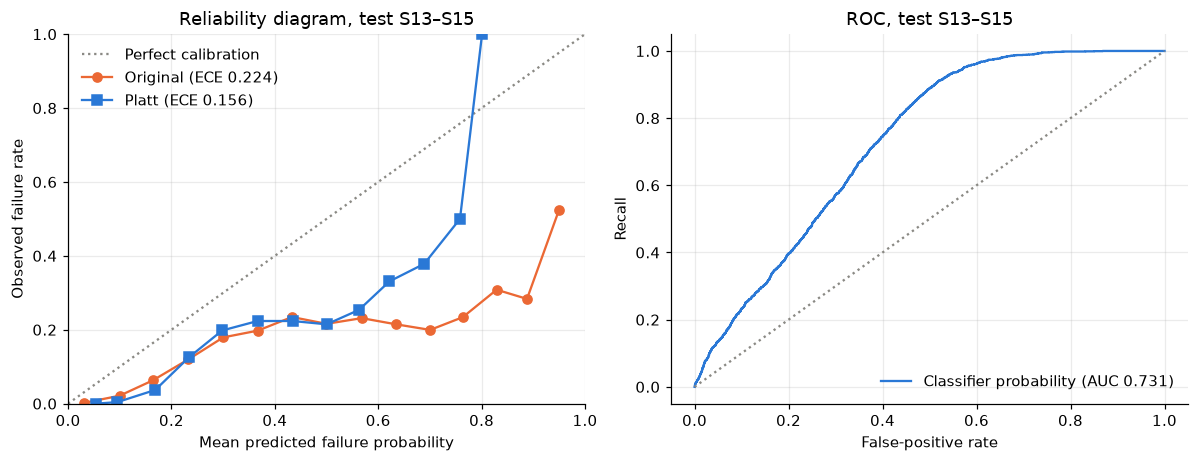

In [9]:
from sklearn.metrics import roc_curve

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))
a1.plot([0, 1], [0, 1], ls=":", color=GREY, label="Perfect calibration")
for m, c, mk in (("original", ORANGE, "o"), ("platt", BLUE, "s")):
    tbl = pd.DataFrame(reliability_table(y_test, test_probs[m], cal_cfg["ece_bins"]))
    tbl = tbl[tbl["count"] > 0]
    a1.plot(tbl.mean_predicted, tbl.observed_rate, marker=mk, color=c,
            label=f"{m.capitalize()} (ECE {test_cal.set_index('method').loc[m, 'ece']:.3f})")
a1.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted failure probability", ylabel="Observed failure rate",
       title="Reliability diagram, test S13–S15")
a1.legend(frameon=False)

fpr, tpr, _ = roc_curve(y_test, test_inputs[PROB])
a2.plot(fpr, tpr, color=BLUE, label=f"Classifier probability (AUC {o.roc_auc:.3f})")
a2.plot([0, 1], [0, 1], ls=":", color=GREY)
a2.set(xlabel="False-positive rate", ylabel="Recall", title="ROC, test S13–S15")
a2.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

Platt scaling makes the probabilities closer to observed frequencies without changing their ranking (same AUC). Over-prediction remains because failures were much more common in the validation participants (33.7% of windows) than in the test participants (13.9%), a shift that a map fitted on two people cannot anticipate.

## 7. Updated training procedure: reward-variant fitted Q policies

The D2 agent was trained once with the reward TP +2, FP −1.5, FN −2, TN 0 and −0.1 per check. In D3 the false-positive penalty and the check cost are treated as hyperparameters. Six reward settings were each trained on S1–S10 with seeds 42, 43 and 44 (18 policies) using the same backward fitted Q-iteration as D2 (`src/experiments/train_reward_variants.py`). Training is not repeated here; the loss histories saved during training are shown next to the D2 history, together with the D2 CNN training curve that the frozen checkpoint came from. Loss values are only comparable between policies trained with the same reward: a larger false-positive penalty widens the range of returns, so its loss is higher in absolute terms.

,variant,false_positive_penalty,investigation_cost
0,original_reward_retrain,-1.5,0.10
1,fp2.0,-2.0,0.10
2,fp2.5,-2.5,0.10
3,fp3.0,-3.0,0.10
4,cost0.05,-1.5,0.05
5,cost0.2,-1.5,0.20


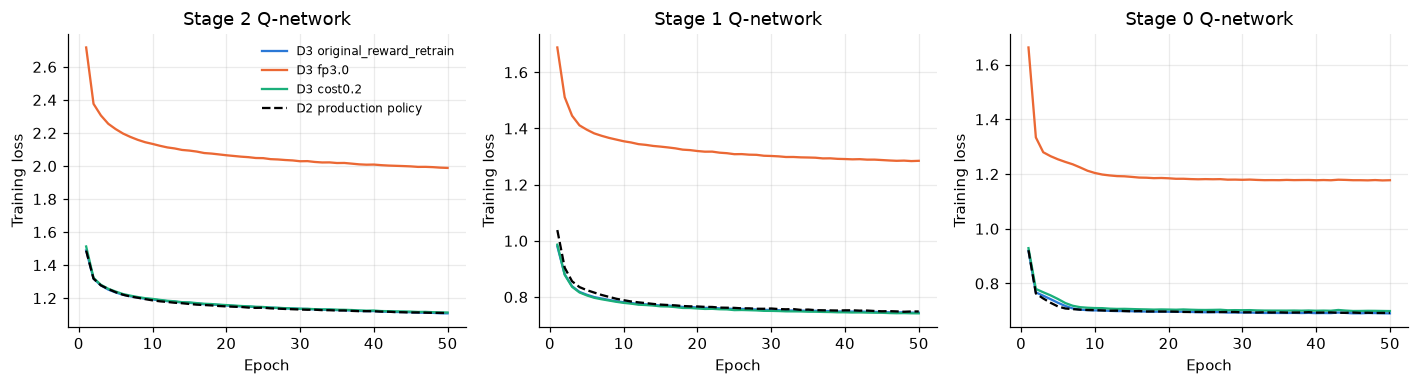

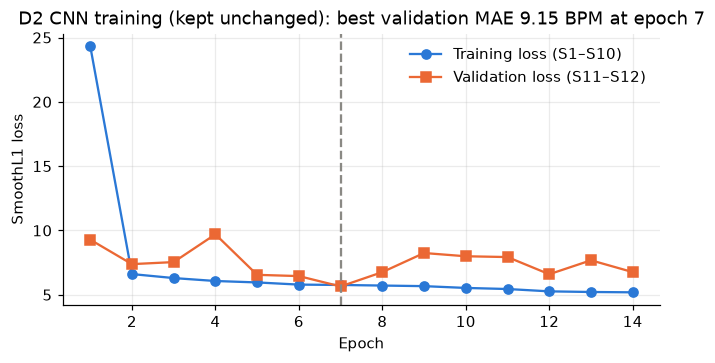

In [10]:
rv_cfg = load_config("phase2_fp_reduction")["families"]["reward_retrained_policy"]
display(pd.DataFrame(rv_cfg["variants"]).T.rename_axis("variant").reset_index())

d2_hist = pd.read_csv(ROOT / "results/metrics/fitted_q_full_training.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, stage in zip(axes, sorted(d2_hist.stage.unique(), reverse=True)):
    for name, color in (("original_reward_retrain", BLUE), ("fp3.0", ORANGE), ("cost0.2", AQUA)):
        h = pd.read_csv(str(variant_path(name, 42)).replace(".pt", ".history.csv"))
        h = h[h.stage == stage]
        ax.plot(h.epoch, h.loss, color=color, label=f"D3 {name}")
    d = d2_hist[d2_hist.stage == stage]
    ax.plot(d.epoch, d.loss, color="black", ls="--", label="D2 production policy")
    ax.set(title=f"Stage {stage} Q-network", xlabel="Epoch", ylabel="Training loss")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

cnn_hist = pd.read_csv(ROOT / "results/metrics/ppg_cnn_training_history.csv")
best = cnn_hist.loc[cnn_hist.val_mae.idxmin()]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(cnn_hist.epoch, cnn_hist.train_loss, marker="o", color=BLUE, label="Training loss (S1–S10)")
ax.plot(cnn_hist.epoch, cnn_hist.val_loss, marker="s", color=ORANGE, label="Validation loss (S11–S12)")
ax.axvline(best.epoch, color=GREY, ls="--")
ax.set(xlabel="Epoch", ylabel="SmoothL1 loss",
       title=f"D2 CNN training (kept unchanged): best validation MAE {best.val_mae:.2f} BPM at epoch {int(best.epoch)}")
ax.legend(frameon=False)
plt.show()

## 8. Validation-only selection of false-positive reduction candidates

The selection rule was fixed before any test evaluation: **lowest validation false-positive rate among candidates whose validation recall is at least the D2 agent's recall minus 5 points; ties broken by F1.** Four families are scored on S11–S12:

- calibrated probability thresholds with no investigation,
- the unchanged D2 agent plus a calibrated veto (a flag is kept only if $p_{cal} \ge \tau$),
- a cost-based rule that flags at the expected-reward break-even probability,
- the 18 retrained policies (seed means are used for selection).

All rewards are reported under the original D2 reward so that candidates are comparable.

In [11]:
fp_cfg = load_config("phase2_fp_reduction")
platt = calibrators["platt"]
variants, seeds = list(rv_cfg["variants"]), rv_cfg["seeds"]

if DATA_AVAILABLE:
    _, val_signals = load_split("validation")
    start = time.perf_counter()
    val_retrained = {(n, s): replay_policy(variant_path(n, s), val_inputs, val_signals) for n in variants for s in seeds}
    print(f"Replayed {len(val_retrained)} retrained policies on validation in {time.perf_counter() - start:.0f} s")
    validation = candidate_rows("validation", val_inputs, frozen_learned(VAL_DECISIONS), platt, fp_cfg, val_retrained)
else:
    print("Processed recordings not found: retrained-policy validation rows loaded from the saved file.")
    saved_val = pd.read_csv(EXP / "phase2_fp_reduction/validation_candidates.csv")
    validation = pd.concat([
        candidate_rows("validation", val_inputs, frozen_learned(VAL_DECISIONS), platt, fp_cfg, {}),
        saved_val[saved_val.family == "reward_retrained_policy"]], ignore_index=True)

saved_val = pd.read_csv(EXP / "phase2_fp_reduction/validation_candidates.csv")
cmp = validation.merge(saved_val, on=["family", "variant", "seed"], suffixes=("", "_saved"), how="outer")
for col in ("recall", "false_positive_rate", "f1", "average_reward"):
    assert np.allclose(cmp[col], cmp[f"{col}_saved"], equal_nan=True), col
print(f"{len(validation)} validation candidates recomputed; all match the saved D3 results.")

floor, per_family, overall = select(validation, fp_cfg)
print(f"Recall floor on validation: {floor:.3f}")
display(per_family[["family", "variant", "recall", "false_positive_rate", "f1", "average_investigations"]].round(3))
print("Selected overall by the rule:", overall[["family", "variant"]].to_dict("records"))

Replayed 18 retrained policies on validation in 96 s
205 validation candidates recomputed; all match the saved D3 results.
Recall floor on validation: 0.807


,family,variant,recall,false_positive_rate,f1,average_investigations
192,reward_retrained_policy,original_reward_retrain,0.812,0.346,0.651,1.289
113,agent_calibrated_veto,tau=0.26,0.813,0.367,0.641,0.860
26,probability_threshold,tau=0.30,0.814,0.440,0.607,0.000
183,bayes_cost_rule,fp=-1.5,0.855,0.480,0.610,0.000


Selected overall by the rule: [{'family': 'reward_retrained_policy', 'variant': 'original_reward_retrain'}]


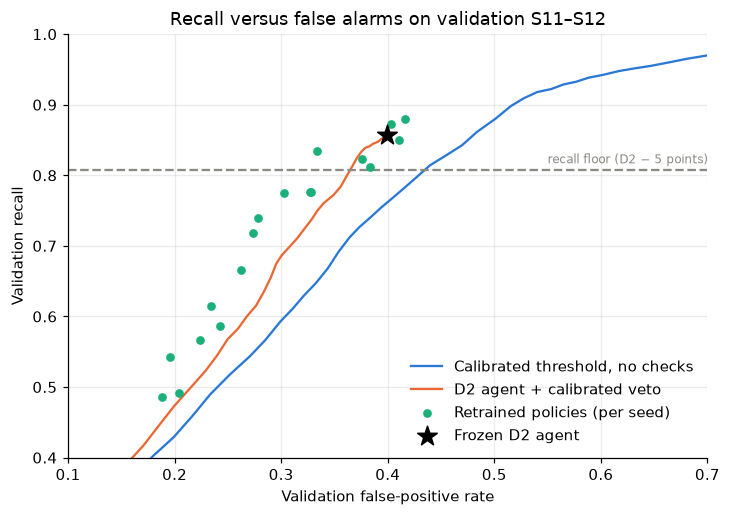

**Reward sensitivity on validation (mean over seeds 42–44)**

,variant,recall,recall_seed_sd,false_positive_rate,false_positive_rate_seed_sd,f1,average_investigations
0,cost0.05,0.788,0.020,0.338,0.042,0.643,1.598
1,cost0.2,0.868,0.015,0.410,0.007,0.649,0.408
2,fp2.0,0.708,0.038,0.271,0.008,0.631,1.452
3,fp2.5,0.589,0.024,0.234,0.009,0.575,1.374
4,fp3.0,0.507,0.031,0.196,0.008,0.535,1.305
5,original_reward_retrain,0.812,0.031,0.346,0.026,0.651,1.289


In [12]:
v = seed_means(validation)
fig, ax = plt.subplots(figsize=(7.5, 5))
thr = v[v.family == "probability_threshold"].sort_values("false_positive_rate")
veto = v[v.family == "agent_calibrated_veto"].sort_values("false_positive_rate")
ax.plot(thr.false_positive_rate, thr.recall, color=BLUE, label="Calibrated threshold, no checks")
ax.plot(veto.false_positive_rate, veto.recall, color=ORANGE, label="D2 agent + calibrated veto")
rt = validation[validation.family == "reward_retrained_policy"]
ax.scatter(rt.false_positive_rate, rt.recall, color=AQUA, s=22, zorder=4, label="Retrained policies (per seed)")
orig = v[v.family == "original_learned"].iloc[0]
ax.scatter(orig.false_positive_rate, orig.recall, marker="*", s=180, color="black", zorder=5, label="Frozen D2 agent")
ax.axhline(floor, ls="--", color=GREY)
ax.text(0.55, floor + 0.01, "recall floor (D2 − 5 points)", color=GREY, fontsize=8)
ax.set(xlim=(0.1, 0.7), ylim=(0.4, 1.0), xlabel="Validation false-positive rate", ylabel="Validation recall",
       title="Recall versus false alarms on validation S11–S12")
ax.legend(frameon=False, loc="lower right")
plt.show()

rs = seed_means(validation[validation.family == "reward_retrained_policy"])
rs = rs[rs.seed == "mean"][["variant", "recall", "recall_seed_sd", "false_positive_rate",
                            "false_positive_rate_seed_sd", "f1", "average_investigations"]]
display(Markdown("**Reward sensitivity on validation (mean over seeds 42–44)**"))
display(rs.round(3))

Raising the false-positive penalty lowers false alarms as intended, but recall falls faster, so every penalised variant drops below the recall floor. The veto curve lies above the threshold-only curve at every false-positive rate, which means the agent's checks add information the probability alone does not have.

## 9. One-time held-out test evaluation: D2 versus D3

Only the candidates chosen on validation are reported. The frozen D2 rows come from the frozen D2 file and are recomputed here from the frozen decisions as a check.

In [13]:
chosen = per_family.loc[per_family.family == "reward_retrained_policy", "variant"].tolist()
saved_dec = {(n, s): pd.read_csv(EXP / f"phase2_fp_reduction/test_decisions_{n}_seed{s}.csv") for n in chosen for s in seeds}
if DATA_AVAILABLE:
    test_retrained = {(n, s): replay_policy(variant_path(n, s), test_inputs, test_signals) for n in chosen for s in seeds}
    for key, frame in test_retrained.items():
        a = frame.sort_values(KEYS).reset_index(drop=True)
        b = saved_dec[key].sort_values(KEYS).reset_index(drop=True)
        assert (a.predicted_unreliable == b.predicted_unreliable).all() and (a.actions == b.actions).all(), key
    print(f"Replayed {len(test_retrained)} selected retrained policies on test; decisions match the saved D3 files.")
else:
    test_retrained = saved_dec
    print("Processed recordings not found: selected retrained-policy test decisions loaded from saved files.")

test_all = seed_means(candidate_rows("test", test_inputs, frozen_learned(TEST_DECISIONS), platt, fp_cfg, test_retrained))
frozen = pd.read_csv(FINAL / "test_policy_comparison.csv")
learned_check = test_all[test_all.family == "original_learned"].iloc[0]
learned_frozen = frozen[frozen.policy == "Learned Fitted Q"].iloc[0]
for k in ("recall", "false_positive_rate", "f1", "average_reward"):
    assert abs(learned_check[k] - learned_frozen[k]) < 1e-9, k

cols = ["accuracy", "precision", "recall", "f1", "false_positive_rate", "average_investigations", "average_reward"]
d2 = frozen.assign(stage="D2 (frozen)", name=frozen.policy)[["stage", "name"] + cols]
picked = test_all.merge(per_family[["family", "variant"]], on=["family", "variant"])
labels = {"probability_threshold": "Calibrated threshold", "agent_calibrated_veto": "D2 agent + calibrated veto",
          "bayes_cost_rule": "Cost-based rule", "reward_retrained_policy": "Retrained policy (mean of 3 seeds)"}
d3 = picked.assign(stage="D3", name=lambda d: d.family.map(labels) + " [" + d.variant + "]")[["stage", "name"] + cols]
comparison = pd.concat([d2, d3], ignore_index=True)

saved_cmp = pd.read_csv(EXP / "phase2_fp_reduction/test_comparison.csv")
for _, r in picked.iterrows():
    s_ = saved_cmp[(saved_cmp.family == r.family) & (saved_cmp.variant == r.variant)].iloc[0]
    assert np.isclose(r.recall, s_.recall) and np.isclose(r.false_positive_rate, s_.false_positive_rate)

shown = comparison.copy()
for c in ("accuracy", "precision", "recall", "false_positive_rate"):
    shown[c] = (100 * shown[c]).round(1)
display(Markdown("**Held-out test S13–S15, 13,007 windows (percent except F1, checks and reward)**"))
display(shown.round(3))

Replayed 3 selected retrained policies on test; decisions match the saved D3 files.


**Held-out test S13–S15, 13,007 windows (percent except F1, checks and reward)**

,stage,name,accuracy,precision,recall,f1,false_positive_rate,average_investigations,average_reward
0,D2 (frozen),Fixed Rule,68.3,26.1,70.3,0.381,32.0,1.037,-0.404
1,D2 (frozen),Learned Fitted Q,64.2,26.4,88.1,0.406,39.6,0.958,-0.396
2,D2 (frozen),No Investigation,67.4,23.3,58.7,0.333,31.2,0.000,-0.355
3,D3,Calibrated threshold [tau=0.30],61.3,23.0,76.5,0.354,41.2,0.000,-0.385
4,D3,D2 agent + calibrated veto [tau=0.26],66.9,26.9,80.9,0.404,35.4,0.958,-0.382
5,D3,Cost-based rule [fp=-1.5],58.2,22.7,83.7,0.357,46.0,0.000,-0.407
6,D3,Retrained policy (mean of 3 seeds) [original_r...,68.1,28.3,84.3,0.424,34.5,1.277,-0.383


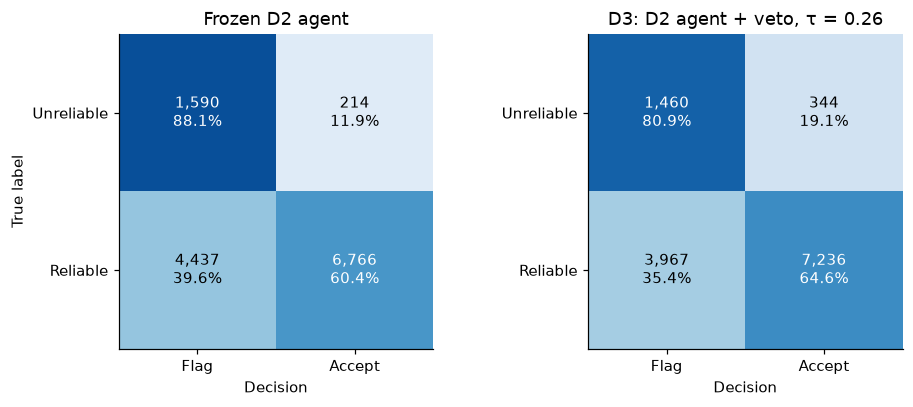

Veto removes 470 false flags and adds 130 missed failures.


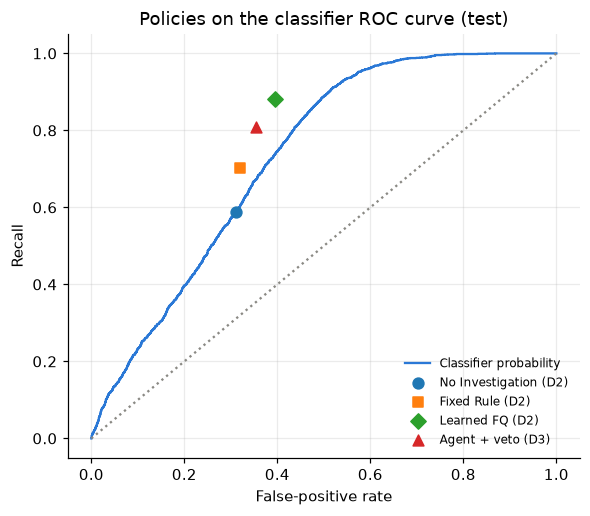

In [14]:
allc = candidate_rows("test", test_inputs, frozen_learned(TEST_DECISIONS), platt, fp_cfg, {})
veto_row = allc[(allc.family == "agent_calibrated_veto") & (allc.variant == "tau=0.26")].iloc[0]
pairs = [("Frozen D2 agent", learned_frozen), ("D3: D2 agent + veto, τ = 0.26", veto_row)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, r) in zip(axes, pairs):
    M = np.array([[r.true_positives, r.false_negatives], [r.false_positives, r.true_negatives]], dtype=float)
    rows = M / M.sum(1, keepdims=True)
    ax.imshow(rows, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(M[i, j]):,}\n{rows[i, j]:.1%}", ha="center", va="center",
                    color="white" if rows[i, j] > .55 else "black")
    ax.set_xticks([0, 1], ["Flag", "Accept"])
    ax.set_yticks([0, 1], ["Unreliable", "Reliable"])
    ax.set(title=title, xlabel="Decision")
    ax.grid(False)
axes[0].set_ylabel("True label")
fig.tight_layout()
plt.show()

print(f"Veto removes {int(learned_frozen.false_positives - veto_row.false_positives)} false flags and adds "
      f"{int(veto_row.false_negatives - learned_frozen.false_negatives)} missed failures.")

fpr, tpr, _ = roc_curve(y_test, test_inputs[PROB])
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color=BLUE, label="Classifier probability")
ax.plot([0, 1], [0, 1], ls=":", color=GREY)
for name, r, mk in [("No Investigation (D2)", frozen.set_index("policy").loc["No Investigation"], "o"),
                    ("Fixed Rule (D2)", frozen.set_index("policy").loc["Fixed Rule"], "s"),
                    ("Learned FQ (D2)", learned_frozen, "D"), ("Agent + veto (D3)", veto_row, "^")]:
    ax.scatter(r.false_positive_rate, r.recall, marker=mk, s=50, zorder=5, label=name)
ax.set(xlabel="False-positive rate", ylabel="Recall", title="Policies on the classifier ROC curve (test)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.show()

**Reading the comparison.** No D3 candidate improves recall and false alarms at the same time. The calibrated veto is a deliberate alternative operating point: 4.2 points lower false-positive rate for 7.2 points lower recall. The retrained policy has the best F1 but its seed-to-seed spread is as large as its gain, so it is treated as training variance rather than a better method. Agent-based points lie above the classifier's ROC curve, so the investigations recover failures that the probability alone ranks low.

## 10. Robustness: synthetic perturbations and natural motion

The 18-condition synthetic study was run by `src/experiments/run_robustness.py` and is loaded here. The natural-motion analysis is recomputed from the recordings when they are available.

In [15]:
syn = pd.read_csv(EXP / "phase3_robustness/synthetic_summary.csv")
wide = syn.pivot_table(index=["perturbation", "level"], columns="policy",
                       values=["recall", "false_positive_rate"]).round(3)
first = syn.drop_duplicates(["perturbation", "level"]).set_index(["perturbation", "level"])
wide.insert(0, ("CNN MAE", ""), first.cnn_mae_bpm.round(2))
wide.insert(1, ("unreliable rate", ""), first.unreliable_rate.round(3))
wide.insert(2, ("classifier AUC", ""), first.classifier_roc_auc.round(3))
display(wide)

CNN MAE unreliable rate classifier AUC false_positive_rate                                       recall                   \
policy                                                                               Fixed Rule Learned Fitted Q No Investigation Fixed Rule Learned Fitted Q   
perturbation                   level                                                                                                                            
accelerometer_coupled_artifact 0.25     9.80           0.376          0.662               0.467            0.594            0.490      0.770            0.920   
                               0.50    15.86           0.572          0.715               0.607            0.721            0.642      0.896            0.973   
                               1.00    23.96           0.733          0.724               0.764            0.853            0.804      0.948            0.985   
amplitude_attenuation          0.25     6.93           0.209          0.792               0.118            0.285            0.066      0.535            0.724   
                               0.50     5.56           0.141          0.779               0.144            0.306            0.099      0.534            0.829   
baseline_wander                1.00     6.75           0.204          0.685               0.305            0.358            0.301      0.617            0.750   
clean                          0.00     5.40           0.139          0.731               0.320            0.396            0.312      0.704            0.881   
clipping                       0.10     5.46           0.152          0.769               0.241            0.359            0.216      0.663            0.895   
                               0.20     6.49           0.200          0.820               0.158            0.326            0.115      0.610            0.896   
gaussian_noise                 0.05     5.45           0.147          0.736               0.355            0.425            0.357      0.764            0.915   
                               0.10     6.73           0.228          0.711               0.419            0.476            0.445      0.791            0.926   
                               0.20    11.82           0.476          0.643               0.625            0.687            0.687      0.848            0.951   
                               0.50    22.35           0.758          0.746               0.897            0.941            0.961      0.988            0.998   
periodic_motion_artifact       0.25     5.97           0.171          0.691               0.353            0.425            0.346      0.698            0.842   
                               0.50     8.49           0.314          0.604               0.528            0.541            0.529      0.752            0.839   
                               1.00    17.71           0.685          0.412               0.947            0.950            0.919      0.931            0.970   
signal_dropout                 1.00     7.12           0.244          0.791               0.241            0.354            0.214      0.695            0.866   
                               2.00     8.52           0.312          0.816               0.180            0.327            0.129      0.655            0.845   

                                                       
policy                               No Investigation  
perturbation                   level                   
accelerometer_coupled_artifact 0.25             0.676  
                               0.50             0.866  
                               1.00             0.943  
amplitude_attenuation          0.25             0.248  
                               0.50             0.303  
baseline_wander                1.00             0.480  
clean                          0.00             0.587  
clipping                       0.10             0.518  
                               0.20    

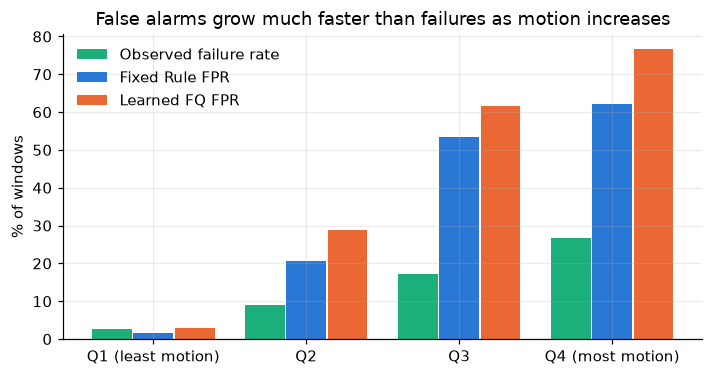

**Frozen D2 agent per test participant**

,subject,windows,unreliable_rate,recall,false_positive_rate,f1
1,13,4565,0.113,0.942,0.379,0.385
4,14,4476,0.130,0.826,0.482,0.326
7,15,3966,0.178,0.882,0.315,0.529


In [16]:
saved_nm = pd.read_csv(EXP / "phase3_robustness/natural_motion_subgroups.csv")
if DATA_AVAILABLE:
    edges = np.quantile(intensity.motion_g, [0, .25, .5, .75, 1])
    intensity["quartile"] = pd.cut(intensity.motion_g, edges, labels=["Q1", "Q2", "Q3", "Q4"], include_lowest=True)
    dec = pd.read_csv(TEST_DECISIONS).merge(intensity, on=KEYS)
    rows = []
    for (q, pol), g in dec.groupby(["quartile", "policy"], observed=True):
        rows.append({"quartile": q, "policy": pol, "unreliable_rate": g.unreliable_target.mean(),
                     **classification_metrics(g.unreliable_target, g.predicted_unreliable)})
    nm = pd.DataFrame(rows)
    a = nm[nm.policy == "Learned Fitted Q"].false_positive_rate.to_numpy()
    b = saved_nm[saved_nm.policy == "Learned Fitted Q"].false_positive_rate.to_numpy()
    assert np.allclose(a, b)
else:
    nm = saved_nm.assign(quartile=["Q1", "Q2", "Q3", "Q4"] * 3)

lf = nm[nm.policy == "Learned Fitted Q"].reset_index(drop=True)
fr = nm[nm.policy == "Fixed Rule"].reset_index(drop=True)
x = np.arange(4)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(x - .27, 100 * lf.unreliable_rate, .26, color=AQUA, label="Observed failure rate")
ax.bar(x, 100 * fr.false_positive_rate, .26, color=BLUE, label="Fixed Rule FPR")
ax.bar(x + .27, 100 * lf.false_positive_rate, .26, color=ORANGE, label="Learned FQ FPR")
ax.set_xticks(x, ["Q1 (least motion)", "Q2", "Q3", "Q4 (most motion)"])
ax.set(ylabel="% of windows", title="False alarms grow much faster than failures as motion increases")
ax.legend(frameon=False)
plt.show()

pp = pd.read_csv(EXP / "phase3_robustness/participant_level_frozen.csv")
pp = pp.assign(unreliable_rate=(pp.true_positives + pp.false_negatives) / pp.windows)
display(Markdown("**Frozen D2 agent per test participant**"))
display(pp[pp.policy == "Learned Fitted Q"][["subject", "windows", "unreliable_rate", "recall",
                                             "false_positive_rate", "f1"]].round(3))

## 11. Qualitative examples

Four recorded decisions of the frozen D2 agent on test windows. The reference heart rate is shown only to judge the outcome.

,example,subject,window,CNN HR,reference HR,|error|,p,recorded path
0,correct accept,13,24,71.5,73.1,1.7,0.258,CHECK_MOTION → CHECK_PPG → ACCEPT
1,failure caught by investigating,15,526,71.8,137.2,65.3,0.479,CHECK_PPG → CHECK_MOTION → FLAG_UNRELIABLE
2,missed failure,15,520,71.6,133.3,61.6,0.493,CHECK_PPG → ACCEPT
3,false alarm near the 10-BPM boundary,15,7,68.1,77.3,9.1,0.175,CHECK_PPG → CHECK_CONSISTENCY → FLAG_UNRELIABLE


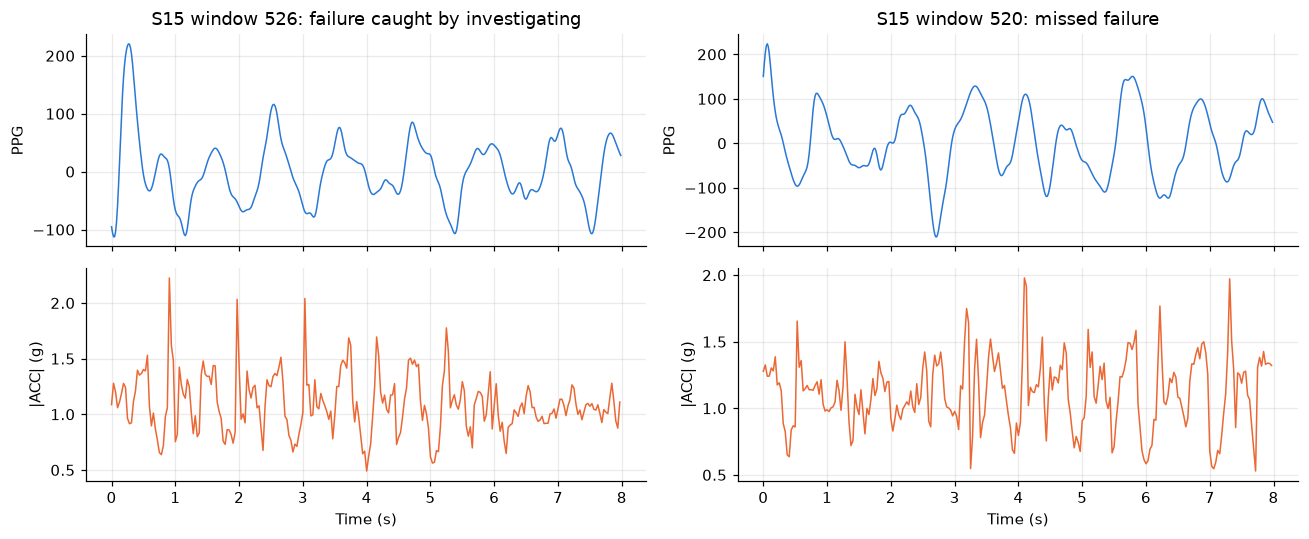

False flags with error between 8 and 10 BPM: 568 of 4,437 (12.8%).
Failures flagged by the agent although p < 0.5 (No Investigation would accept them): 577.


In [17]:
traces = pd.read_csv(ROOT / "results/demo/learned_agent_traces.csv")
examples = [(13, 24, "correct accept"), (15, 526, "failure caught by investigating"),
            (15, 520, "missed failure"), (15, 7, "false alarm near the 10-BPM boundary")]
rows = []
for s, w, kind in examples:
    i = test_inputs[(test_inputs.subject == s) & (test_inputs.window_index == w)].iloc[0]
    t_ = traces[(traces.subject == s) & (traces.window_index == w)].iloc[0]
    rows.append({"example": kind, "subject": s, "window": w, "CNN HR": round(i.cnn_predicted_hr, 1),
                 "reference HR": round(i.reference_hr, 1), "|error|": round(i.absolute_error, 1),
                 "p": round(i.unreliable_probability, 3), "recorded path": t_.actions.replace("|", " → ")})
display(pd.DataFrame(rows))

if DATA_AVAILABLE:
    fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex="col")
    for col, (s, w, kind) in enumerate(examples[1:3]):
        sig = test_signals[s]
        axes[0, col].plot(np.arange(512) / 64, sig["ppg"][w], color=BLUE, lw=1)
        axes[0, col].set(title=f"S{s} window {w}: {kind}", ylabel="PPG")
        mag = np.linalg.norm(sig["acc"][w], axis=1)
        axes[1, col].plot(np.arange(256) / 32, mag, color=ORANGE, lw=1)
        axes[1, col].set(xlabel="Time (s)", ylabel="|ACC| (g)")
    fig.tight_layout()
    plt.show()

dec = frozen_learned(TEST_DECISIONS).merge(test_inputs[KEYS + ["absolute_error"]], on=KEYS)
fps = dec[(dec.predicted_unreliable == 1) & (dec.unreliable_target == 0)]
rescued = dec[(dec.predicted_unreliable == 1) & (dec.unreliable_target == 1) & (dec.unreliable_probability < .5)]
print(f"False flags with error between 8 and 10 BPM: {(fps.absolute_error > 8).sum()} of {len(fps):,} "
      f"({(fps.absolute_error > 8).mean():.1%}).")
print(f"Failures flagged by the agent although p < 0.5 (No Investigation would accept them): {len(rescued)}.")

## 12. Summary

| Area | D2 | D3 |
|---|---|---|
| Probability calibration | test ECE 0.224, Brier 0.194 | Platt, selected on validation: ECE 0.156, Brier 0.140, same AUC |
| False-alarm control | one operating point (recall 88.1%, FPR 39.6%) | measured trade-off; calibrated veto gives FPR 35.4% at recall 80.9%; no variant improves both |
| Policy training | one reward, one seed | 6 reward settings × 3 seeds, compared under the original reward |
| Robustness | clean test only | 18 synthetic conditions and motion quartiles |
| Reproducibility | notebook-based policy training | scripts, pinned dependencies, SHA-256 registry, automated tests, this notebook's assertions |

**Limitations.** Results rest on two validation and three test participants; leave-one-participant-out evaluation of the full system is not done; synthetic perturbations are simplified; false alarms remain high in high-motion windows. MotionProof AI is a research prototype and is not clinically validated.